# Домашнее задание / Ad-hoc аналитика

**Коняхин Никита** 

## 1. ТЗ

**Проблема:** 20 июля CTR top_search на Android резко выше обычного. Причина неизвестна.

| Пункт | Формулировка |
|---|---|
| Цель | Понять, подтверждается ли аномалия в данных и достаточно ли оснований менять формат Android |
| Гипотеза | Скачок связан с дефектом регистрации кликов; альтернатива это реальное изменение поведения или состава трафика |
| Метрика | CTR = число показов хотя бы с одним кликом / показы. Доп. отклики / клики и отклики / показы |
| Период | 1–28 июля 2026 года. Основное сравнение: 20 июля против 15–28 июля без 20-го; проверки устойчивости на остальных днях июля и другие понедельники |
| Сегменты | Платформа, продукт, сегмент работодателя. Основной анализ только top_search |
| Критерий успеха | Подтверждаем скачок CTR сравнением долей и интервалами. Ошибку трекинга считаем доказанной только при прямом дефекте событий или подтверждении логами. Для смены формата нужен подтверждённый рост целевого действия и проверенный трекинг |
| Решение | При дефекте нужно исправить логирование и пересчитать. При корректном трекинге надо проверить изменение формата A/B-тестом. При недостатке доказательств сохранить формат и собрать диагностику |

Порог бизнеса и дедлайн в условии не заданы.
Статистические сравнения ниже разведочные, с уровнем 5%.

**Глубина** Сделаем разбор, ибо цена ошибки средняя тк по результату можно изменить интерфейс и ухудшить воронку.
Формат можно вернуть флагом, поэтому для первичного решения нужны качество данных, сравнения, разрезы и интервалы.

## 2. Подготовка окружения

In [1]:
from pathlib import Path
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from IPython.display import display

plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

DATA = Path('data')

OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)

try:
    import duckdb
    con = duckdb.connect()
    ENGINE = 'DuckDB'
except ImportError:
    con = sqlite3.connect(':memory:')
    ENGINE = 'SQLite'

def register_csv(name, filename):
    df = pd.read_csv(DATA / filename, dtype={'year': str, 'month': str, 'day': str})
    if ENGINE == 'DuckDB':
        con.register(name, df)
    else:
        df.to_sql(name, con, index=False, if_exists='replace')
    print(f'{name:20s} {len(df):>8,} строк')
    return df

impressions = register_csv('impressions', 'impressions.csv')
clicks = register_csv('clicks', 'clicks.csv')
responses = register_csv('responses', 'responses.csv')
product_daily = register_csv('product_daily', 'product_daily.csv')

def sql(query):
    if ENGINE == 'DuckDB':
        return con.execute(query).df()
    return pd.read_sql_query(query, con)

print('SQL-движок:', ENGINE)


impressions            80,000 строк
clicks                  3,837 строк
responses                 421 строк
product_daily             252 строк
SQL-движок: SQLite


Используем интервал Уилсона для доли и сводку качества данных. Интервал показывает неопределённость доли, но сам по себе не объясняет причину изменения. Для сравнения долей используем также точный критерий Фишера.

In [2]:
def wilson_ci(successes, n, z=1.96):
    if n <= 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return max(0, center - margin), min(1, center + margin)

def proportion_table(df, group_cols, success_col, n_col, rate_name='rate'):
    g = df.groupby(group_cols, as_index=False).agg(
        successes=(success_col, 'sum'), n=(n_col, 'sum')
    )
    g[rate_name] = g['successes'] / g['n']
    cis = g.apply(lambda r: wilson_ci(r['successes'], r['n']), axis=1)
    g['ci_low'] = cis.map(lambda x: x[0])
    g['ci_high'] = cis.map(lambda x: x[1])
    return g

def summarize_dq(df, key_cols):
    return pd.DataFrame({
        'проверка': ['строк', 'полных дублей', 'дублей ключа', 'пропусков'],
        'значение': [len(df), df.duplicated().sum(),
                     df.duplicated(key_cols).sum(), df.isna().sum().sum()]
    })


## 3. Качество данных

In [3]:
for name, df, key in [
    ('impressions', impressions, 'impression_id'),
    ('clicks', clicks, 'click_id'),
    ('responses', responses, 'response_id')
]:
    print(name)
    display(summarize_dq(df, [key]))
    dates = pd.to_datetime(df['event_date'], errors='coerce')
    print('Период:', dates.min().date(), '-', dates.max().date())
    print('Невалидных дат:', dates.isna().sum())
    print('Платформы:', sorted(df['platform'].unique()))
    print('Продукты:', sorted(df['product'].unique()))
    partition_date = pd.to_datetime(df[['year', 'month', 'day']])
    print('Несовпадений даты и партиций:', (dates != partition_date).sum())
    print()

print('Повторных impression_id в кликах:', clicks['impression_id'].duplicated().sum())
print('Повторных click_id в откликах:', responses['click_id'].duplicated().sum())
print('Кликов без показа:', (~clicks['impression_id'].isin(impressions['impression_id'])).sum())
print('Откликов без клика:', (~responses['click_id'].isin(clicks['click_id'])).sum())
print('Откликов без показа:', (~responses['impression_id'].isin(impressions['impression_id'])).sum())

fields = ['event_date', 'platform', 'product', 'segment',
          'vacancy_id', 'employer_id', 'hhuid']
for child, parent, key, label in [
    (clicks, impressions, 'impression_id', 'клик - показ'),
    (responses, clicks, 'click_id', 'отклик - клик')
]:
    joined = child.merge(parent, on=key, suffixes=('_child', '_parent'), validate='many_to_one')
    mismatch = {c: int((joined[c + '_child'] != joined[c + '_parent']).sum()) for c in fields}
    if key == 'click_id':
        mismatch['impression_id'] = int((joined['impression_id_child'] != joined['impression_id_parent']).sum())
    print(label, mismatch)


impressions


,проверка,значение
0,строк,80000
1,полных дублей,0
2,дублей ключа,0
3,пропусков,0


Период: 2026-07-01 - 2026-07-28
Невалидных дат: 0
Платформы: ['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
Продукты: ['top_boost', 'top_search']
Несовпадений даты и партиций: 0

clicks


,проверка,значение
0,строк,3837
1,полных дублей,0
2,дублей ключа,0
3,пропусков,0


Период: 2026-07-01 - 2026-07-28
Невалидных дат: 0
Платформы: ['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
Продукты: ['top_boost', 'top_search']
Несовпадений даты и партиций: 0

responses


,проверка,значение
0,строк,421
1,полных дублей,0
2,дублей ключа,0
3,пропусков,0


Период: 2026-07-01 - 2026-07-28
Невалидных дат: 0
Платформы: ['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
Продукты: ['top_boost', 'top_search']
Несовпадений даты и партиций: 0

Повторных impression_id в кликах: 0
Повторных click_id в откликах: 0
Кликов без показа: 0
Откликов без клика: 0
Откликов без показа: 0
клик - показ {'event_date': 0, 'platform': 0, 'product': 0, 'segment': 0, 'vacancy_id': 0, 'employer_id': 0, 'hhuid': 0}
отклик - клик {'event_date': 0, 'platform': 0, 'product': 0, 'segment': 0, 'vacancy_id': 0, 'employer_id': 0, 'hhuid': 0, 'impression_id': 0}


**Что имеем.** В таблицах 80 000 показов, 3 837 кликов и 421 отклик. Пропусков, полных дублей и повторов первичных ключей нет.
Все клики связаны с показами, все отклики с кликами; проверенные поля связанных событий совпадают. 

Все хорошо, очистка не потребовалась.

## 4. Воронка по дням и платформам
Сначала считаем на уровне показа. Перед соединением сворачиваем клики и отклики до уникальных показов, чтобы JOIN не увеличивал знаменатель.


In [4]:
q_daily = '''
WITH clicked AS (
    SELECT DISTINCT impression_id FROM clicks
), responded AS (
    SELECT DISTINCT impression_id FROM responses
)
SELECT
    i.event_date,
    i.platform,
    i.segment,
    COUNT(*) AS impressions,
    SUM(CASE WHEN c.impression_id IS NOT NULL THEN 1 ELSE 0 END) AS clicks,
    SUM(CASE WHEN r.impression_id IS NOT NULL THEN 1 ELSE 0 END) AS responses
FROM impressions i
LEFT JOIN clicked c ON c.impression_id = i.impression_id
LEFT JOIN responded r ON r.impression_id = i.impression_id
WHERE i.product = 'top_search'
  AND i.year = '2026' AND i.month = '07'
  AND i.day BETWEEN '01' AND '28'
GROUP BY i.event_date, i.platform, i.segment
ORDER BY i.event_date, i.platform, i.segment
'''

daily_segment = sql(q_daily)
daily = daily_segment.groupby(['event_date', 'platform'], as_index=False)[
    ['impressions', 'clicks', 'responses']
].sum()
daily['ctr'] = daily['clicks'] / daily['impressions']

# После 15 июля появился top_boost: основной фон берём после запуска.
comparison = daily[daily['event_date'] >= '2026-07-15'].copy()
comparison['period'] = np.where(comparison['event_date'] == '2026-07-20',
                                '20 июля', '15–28 июля без 20-го')
funnel = comparison.groupby(['platform', 'period'], as_index=False).agg(
    impressions=('impressions', 'sum'), clicks=('clicks', 'sum'), responses=('responses', 'sum')
)
funnel['ctr_pct'] = 100 * funnel['clicks'] / funnel['impressions']
funnel['cvr_pct'] = 100 * funnel['responses'] / funnel['clicks']
funnel['response_rate_pct'] = 100 * funnel['responses'] / funnel['impressions']
display(funnel.round(3))


,platform,period,impressions,clicks,responses,ctr_pct,cvr_pct,response_rate_pct
0,ANDROID,15–28 июля без 20-го,4990,147,22,2.946,14.966,0.441
1,ANDROID,20 июля,383,36,4,9.399,11.111,1.044
2,DESKTOP_WEB,15–28 июля без 20-го,8546,463,42,5.418,9.071,0.491
3,DESKTOP_WEB,20 июля,714,47,3,6.583,6.383,0.420
4,IOS,15–28 июля без 20-го,4239,145,30,3.421,20.690,0.708
5,IOS,20 июля,293,9,2,3.072,22.222,0.683
6,MOBILE_WEB,15–28 июля без 20-го,4972,243,27,4.887,11.111,0.543
7,MOBILE_WEB,20 июля,406,32,4,7.882,12.500,0.985


### График 1. CTR с доверительным интервалом
Сравниваем 20 июля с остальными днями после появления top_boost.

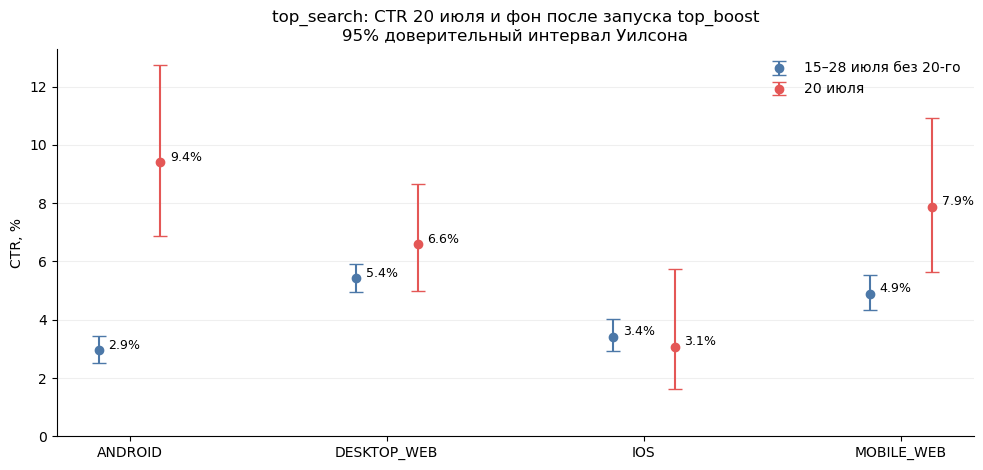

,platform,period,successes,n,ctr,ci_low,ci_high
0,ANDROID,15–28 июля без 20-го,147,4990,0.02946,0.02512,0.03452
1,ANDROID,20 июля,36,383,0.09399,0.06867,0.12739


In [5]:
ctr_ci = proportion_table(comparison, ['platform', 'period'], 'clicks', 'impressions', 'ctr')
platforms = ['ANDROID', 'DESKTOP_WEB', 'IOS', 'MOBILE_WEB']
periods = ['15–28 июля без 20-го', '20 июля']
colors = ['#4C78A8', '#E45756']

fig, ax = plt.subplots(figsize=(10, 4.8))
for offset, period, color in zip([-0.12, 0.12], periods, colors):
    part = ctr_ci[ctr_ci['period'] == period].set_index('platform').loc[platforms]
    x = np.arange(len(platforms)) + offset
    ax.errorbar(x, 100 * part['ctr'],
                yerr=[100 * (part['ctr'] - part['ci_low']),
                      100 * (part['ci_high'] - part['ctr'])],
                fmt='o', capsize=5, color=color, label=period)
    for pos, value in zip(x, part['ctr']):
        ax.annotate(f'{value:.1%}', (pos, value * 100), xytext=(7, 1), textcoords='offset points', fontsize=9)
ax.set_xticks(range(len(platforms)), platforms)
ax.set_ylabel('CTR, %')
ax.set_title('top_search: CTR 20 июля и фон после запуска top_boost\n95% доверительный интервал Уилсона')
ax.set_ylim(bottom=0)
ax.grid(axis='y', alpha=0.2)
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig(OUTPUT / '01_ctr_ci.png', dpi=180)
plt.show()

display(ctr_ci[ctr_ci['platform'] == 'ANDROID'].round(5))


### График 2. Распределение дневного CTR
Коробки показывают медиану и межквартильный размах.

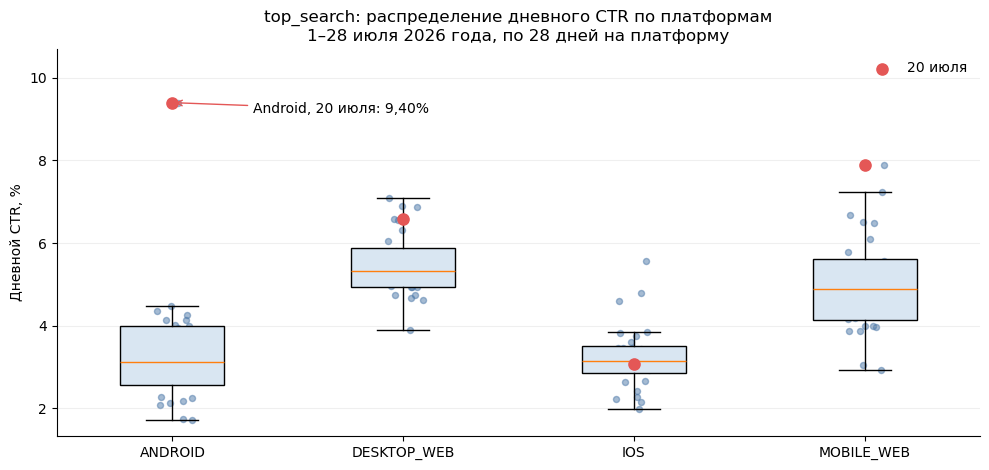

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.8))
values = [100 * daily.loc[daily['platform'] == p, 'ctr'].values for p in platforms]
ax.boxplot(values, tick_labels=platforms, showfliers=False,
           patch_artist=True, boxprops={'facecolor': '#D9E6F2'})
rng = np.random.default_rng(42)
for pos, platform in enumerate(platforms, 1):
    part = daily[daily['platform'] == platform]
    ax.scatter(pos + rng.uniform(-0.09, 0.09, len(part)), 100 * part['ctr'],
               color='#4C78A8', alpha=0.5, s=19)
    value = part.loc[part['event_date'] == '2026-07-20', 'ctr'].iloc[0]
    ax.scatter(pos, 100 * value, color='#E45756', s=65, zorder=5,
               label='20 июля' if pos == 1 else None)
ax.annotate('Android, 20 июля: 9,40%', xy=(1, 100 * values[0].max() / 100),
            xytext=(1.35, 9.15), arrowprops={'arrowstyle': '->', 'color': '#E45756'}, fontsize=10)
ax.set_ylabel('Дневной CTR, %')
ax.set_ylim(top=10.7)
ax.set_title('top_search: распределение дневного CTR по платформам\n1–28 июля 2026 года, по 28 дней на платформу')
ax.grid(axis='y', alpha=0.2)
ax.legend(frameon=False, loc='upper right')
fig.tight_layout()
fig.savefig(OUTPUT / '02_daily_distribution.png', dpi=180)
plt.show()


## 5. Проверка аномалии и целевого действия

In [7]:
android = funnel[funnel['platform'] == 'ANDROID'].set_index('period')
a = android.loc['20 июля']
b = android.loc['15–28 июля без 20-го']

tests = []
for label, success, total in [
    ('CTR', 'clicks', 'impressions'),
    ('Отклики / показы', 'responses', 'impressions'),
    ('Отклики / клики', 'responses', 'clicks')
]:
    _, p = fisher_exact([[int(a[success]), int(a[total] - a[success])],
                         [int(b[success]), int(b[total] - b[success])]])
    lo_a, hi_a = wilson_ci(a[success], a[total])
    lo_b, hi_b = wilson_ci(b[success], b[total])
    tests.append({'метрика': label, '20 июля': a[success] / a[total],
                  'фон': b[success] / b[total], 'p_value': p,
                  'интервал 20 июля': f'{lo_a:.2%}–{hi_a:.2%}',
                  'интервал фона': f'{lo_b:.2%}–{hi_b:.2%}'})
tests = pd.DataFrame(tests)
display(tests)

print(f'CTR Android: {a.clicks:.0f}/{a.impressions:.0f} = {a.ctr_pct:.2f}%')
print(f'Фон: {b.clicks:.0f}/{b.impressions:.0f} = {b.ctr_pct:.2f}%')
print(f'Разница: {a.ctr_pct - b.ctr_pct:.2f} п.п.; отношение: {a.ctr_pct / b.ctr_pct:.2f}')


,метрика,20 июля,фон,p_value,интервал 20 июля,интервал фона
0,CTR,0.093995,0.029459,1.217461e-08,6.87%–12.74%,2.51%–3.45%
1,Отклики / показы,0.010444,0.004409,1.097093e-01,0.41%–2.65%,0.29%–0.67%
2,Отклики / клики,0.111111,0.149660,7.901425e-01,4.41%–25.32%,10.10%–21.62%


CTR Android: 36/383 = 9.40%
Фон: 147/4990 = 2.95%
Разница: 6.45 п.п.; отношение: 3.19


**Результат.** На Android 20 июля было 383 показа, 36 кликов и 4 отклика. В фоне после запуска 4 990 показов, 147 кликов и 22 отклика. CTR вырос с **2,95% до 9,40%**: на **6,45 п.п.**, примерно в **3,19 раза**.

Точный тест подтверждает различие CTR в выбранном сравнении (p ≈ 1,22 × 10⁻⁸).

Отклики / показы выросли с 0,44% до 1,04%, но оценка опирается всего на четыре отклика; p ≈ 0,110.

Отклики / клики составили 11,11% против 14,97%, p ≈ 0,790.
Нельзя утверждать ни доказанный рост целевого действия, ни доказанное отсутствие роста.

## 6. Проверки устойчивости и разрезы

In [8]:
and_daily = daily[daily['platform'] == 'ANDROID'].copy()
and_daily['weekday'] = pd.to_datetime(and_daily['event_date']).dt.dayofweek
backgrounds = {
    '15–28 июля без 20-го': (and_daily['event_date'] >= '2026-07-15') & (and_daily['event_date'] != '2026-07-20'),
    'Все остальные дни июля': and_daily['event_date'] != '2026-07-20',
    'Другие понедельники': (and_daily['weekday'] == 0) & (and_daily['event_date'] != '2026-07-20')
}
rows = []
for label, mask in backgrounds.items():
    part = and_daily[mask]
    n, k = part['impressions'].sum(), part['clicks'].sum()
    rows.append({'фон': label, 'показы': n, 'клики': k, 'ctr_pct': 100 * k / n,
                 'отношение CTR 20 июля к фону': (a.clicks / a.impressions) / (k / n)})
display(pd.DataFrame(rows).round(3))

seg = daily_segment[(daily_segment['platform'] == 'ANDROID') &
                    (daily_segment['event_date'] >= '2026-07-15')].copy()
seg['period'] = np.where(seg['event_date'] == '2026-07-20', '20 июля', 'Фон после запуска')
seg = seg.groupby(['segment', 'period'], as_index=False)[['impressions', 'clicks', 'responses']].sum()
seg['ctr_pct'] = 100 * seg['clicks'] / seg['impressions']
display(seg.round(3))

# Проверяем, заметен ли рост и во втором продукте на Android.
other_product = sql("""
SELECT i.product,
       CASE WHEN i.event_date = '2026-07-20' THEN '20 июля' ELSE 'Фон после запуска' END AS period,
       COUNT(*) AS impressions,
       COUNT(c.click_id) AS clicks
FROM impressions i
LEFT JOIN clicks c ON c.impression_id = i.impression_id
WHERE i.platform = 'ANDROID' AND i.event_date BETWEEN '2026-07-15' AND '2026-07-28'
GROUP BY i.product, CASE WHEN i.event_date = '2026-07-20' THEN '20 июля' ELSE 'Фон после запуска' END
""")
other_product['ctr_pct'] = 100 * other_product['clicks'] / other_product['impressions']
display(other_product.round(3))


,фон,показы,клики,ctr_pct,отношение CTR 20 июля к фону
0,15–28 июля без 20-го,4990,147,2.946,3.191
1,Все остальные дни июля,13898,444,3.195,2.942
2,Другие понедельники,1686,57,3.381,2.780


,segment,period,impressions,clicks,responses,ctr_pct
0,Large,20 июля,111,12,0,10.811
1,Large,Фон после запуска,1528,44,6,2.880
2,Premium,20 июля,62,4,1,6.452
3,Premium,Фон после запуска,777,28,1,3.604
4,SMB,20 июля,210,20,3,9.524
5,SMB,Фон после запуска,2685,75,15,2.793


,product,period,impressions,clicks,ctr_pct
0,top_boost,20 июля,252,29,11.508
1,top_boost,Фон после запуска,3073,136,4.426
2,top_search,20 июля,383,36,9.399
3,top_search,Фон после запуска,4990,147,2.946


**Вывод.** 
При сравнении со всеми остальными днями CTR Android равен 3,19%, с другими понедельниками 3,38%.
На фоне этих периодов 9,40% также выделяется. CTR вырос во всех трёх сегментах работодателей;
в top_boost на Android он тоже выше фона: 11,51% против 4,43%. 
Это повод проверить регистрацию событий на платформе в целом, но техническая причина по этим данным не установлена.

## 7. Бонус: расход после запуска top_boost 15 июля

In [10]:
display(summarize_dq(product_daily, ['event_date', 'product', 'segment']))
spend = product_daily.copy()
spend['period'] = np.where(spend['event_date'] < '2026-07-15', 'before', 'after')
spend_table = spend.groupby(['period', 'product'])['net_spend'].sum().unstack(fill_value=0)
spend_table['total'] = spend_table.sum(axis=1)
display(spend_table.round(2))
old_change = spend_table.loc['after', 'top_search'] / spend_table.loc['before', 'top_search'] - 1
total_change = spend_table.loc['after', 'total'] / spend_table.loc['before', 'total'] - 1
print(f'Изменение top_search: {old_change:.2%}')
print(f'Изменение суммарного расхода: {total_change:.2%}')

spend_segment = spend.groupby(['segment', 'period', 'product'])['net_spend'].sum().unstack(fill_value=0)
spend_segment['total'] = spend_segment.sum(axis=1)
display(spend_segment.round(2))


,проверка,значение
0,строк,252
1,полных дублей,0
2,дублей ключа,0
3,пропусков,0


product,top_boost,top_search,total
period,,,
after,5728188.31,16046478.14,21774666.45
before,0.00,19280463.72,19280463.72


Изменение top_search: -16.77%
Изменение суммарного расхода: 12.94%


product          top_boost  top_search       total
segment period                                    
Large   after   2379734.07  7315100.31  9694834.38
        before        0.00  8150009.27  8150009.27
Premium after   1666472.09  5260649.40  6927121.49
        before        0.00  6094037.67  6094037.67
SMB     after   1681982.15  3470728.43  5152710.58
        before        0.00  5036416.78  5036416.78

**Вывод.** За равные четырёхнедельные окна расход top_search сократился примерно на 16,8%, а общий расход вырос примерно на 12,9%. Появление нового продукта меняет структуру трафика и расходов, поэтому CTR считаем отдельно для top_search и основной фон берём после 15 июля.

Динамика расхода не объясняет однодневный скачок Android.

## 8. Итоговая справка

**Решение**

- Сохранить текущий формат top_search на Android. Проверить регистрацию кликов за 20 июля и не объявлять скачок доказанным улучшением продукта, и не удалять события без подтверждения дефекта.

**Контекст** 
- 20 июля 2026 года CTR Android резко вырос. Нужно выбрать между исправлением трекинга и изменением формата показа.

**Что сделал** 
- Проверил ключи, пропуски, дубли, даты и связи трёх таблиц; собрал воронку top_search по дням,
платформам и сегментам. Сравнил 20 июля с 15–28 июля без 20-го, построил интервалы Уилсона и распределение дневного CTR.
Проверил фон остальных дней и других понедельников.

**Результат** 
- На Android CTR — 36 / 383 = **9,40%**, фон — 147 / 4 990 = **2,95%**.
Разница **6,45 п.п.**, рост в **3,19 раза**. Скачок CTR подтверждается сравнением долей.
Прямых дефектов в выгрузках нет: клики уникальны и связаны с показами.
Четыре отклика не дают уверенного вывода о росте целевого действия: отклики / показы — 1,04% против 0,44%, p ≈ 0,110.

**Ограничения** 
- Нет времени событий, версии приложения, релизов, исходных логов и признаков ботов.
Не проверены окно атрибуции, задержки откликов и поведение за пределами июля.
Доли считаются по показам; повторные показы одному человеку могут нарушать независимость наблюдений.
Дата выбрана после обнаружения выброса; тесты разведочные, без поправки на поиск аномалий.
Другие платформы не являются случайным контролем. Статистическое отличие не устанавливает причину.

**Дальше** 
- Аналитик и команда Android проверяют логи и изменения регистрации событий за 20 июля.
Если ошибка подтверждена — исправляют логирование и пересчитывают показатели. Если трекинг корректен — продакт
проверяет гипотезу формата A/B-тестом по откликам на показ. Ответственных и срок нужно согласовать с командой;
до проверки причин формат сохраняется.
